In [ ]:
import pandas as pd

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
df = pd.read_csv('/content/drive/MyDrive/Dibimbing Data-Engineering Bootcamp 16/healthcare_patient_dataset.csv')
df.head()

,patient_id,age,gender,bmi,blood_pressure_sys,blood_sugar,city,smoker_status,diagnosis_risk
0,8592,53,L,20.2,38.0,103.7,Kota_080,No,Low
1,13051,53,P,30.1,119.1,109.0,Kota_094,No,Low
2,18353,38,P,31.6,136.2,94.3,Kota_096,Yes,Medium
3,18873,63,L,24.3,139.2,117.4,Kota_070,No,Medium
4,19496,49,L,21.2,122.3,137.1,Kota_017,No,Low


# Eksplorasi dataset

In [ ]:
# Melihat informasi dataset dan tipe data
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   patient_id          10000 non-null  int64  
 1   age                 10000 non-null  int64  
 2   gender              10000 non-null  object 
 3   bmi                 9519 non-null   float64
 4   blood_pressure_sys  9238 non-null   float64
 5   blood_sugar         10000 non-null  float64
 6   city                10000 non-null  object 
 7   smoker_status       9400 non-null   object 
 8   diagnosis_risk      10000 non-null  object 
dtypes: float64(3), int64(2), object(4)
memory usage: 703.3+ KB


Dataset healthcare patient memiliki 10.000 baris data dan 9 kolom.

Terdapat tiga jenis tipe data:

* int64: 2 kolom, yaitu patient_id dan age.
* float64: 3 kolom, yaitu bmi, blood_pressure_sys, dan blood_sugar.
* object: 4 kolom, yaitu gender, city, smoker_status, dan diagnosis_risk.

Dari pemeriksaan nilai kosong (missing values), ditemukan:

* bmi
* blood_pressure_sys
* smoker_status

Sementara itu, kolom lainnya memiliki 10.000 data non-null atau tidak memiliki nilai kosong.

Kesimpulan: Dataset memiliki beberapa nilai kosong pada kolom bmi, blood_pressure_sys, dan smoker_status. Hal ini perlu diperhatikan pada tahap data cleaning selanjutnya.

In [ ]:
df.describe()

,patient_id,age,bmi,blood_pressure_sys,blood_sugar
count,10000.000000,10000.000000,9519.000000,9238.000000,10000.00000
mean,10489.029500,48.553900,27.068579,123.365848,133.71597
std,5465.127789,18.484114,15.540204,29.808558,147.70530
min,1000.000000,-14.000000,2.000000,10.000000,31.50000
25%,5787.750000,33.000000,22.300000,113.600000,92.40000
50%,10490.500000,49.000000,25.400000,122.100000,106.10000
75%,15220.750000,64.000000,28.700000,130.600000,120.30000
max,19998.000000,194.000000,158.900000,318.800000,1196.90000


Statistik dari kolom numerik:

* Age: Rata-rata usia pasien adalah 48,55 tahun, dengan nilai minimum -14 dan maksimum 194 tahun. Nilai tersebut perlu diperiksa karena tidak wajar untuk usia pasien.
* BMI: Rata-rata BMI adalah 27,07, dengan nilai minimum 2 dan maksimum 158,9. Terdapat nilai yang berpotensi tidak normal.
* Blood Pressure Sys: Rata-rata tekanan darah sistolik adalah 123,37, dengan nilai minimum 10 dan maksimum 318,8. Rentang nilai tersebut perlu diperiksa lebih lanjut.
* Blood Sugar: Rata-rata kadar gula darah adalah 133,72, dengan nilai minimum 31,5 dan maksimum 1.196,9. Nilai maksimum terlihat sangat tinggi sehingga perlu diperiksa.

Jumlah data pada kolom bmi dan blood_pressure_sys lebih sedikit dibandingkan jumlah keseluruhan data karena terdapat missing values.

Kesimpulan: Hasil eksplorasi menunjukkan adanya nilai yang berpotensi tidak wajar (outliers atau invalid values), khususnya pada kolom age, bmi, blood_pressure_sys, dan blood_sugar. Nilai-nilai tersebut perlu dianalisis lebih lanjut.

# Penanganan Missing Value

In [ ]:
# Memeriksa kembali jumlah missing values
df.isnull().sum()

,0
patient_id,0
age,0
gender,0
bmi,481
blood_pressure_sys,762
blood_sugar,0
city,0
smoker_status,600
diagnosis_risk,0


Metode:

* bmi → Median
* blood_pressure_sys → Median
* smoker_status → Modus

Alasan:

Metode median digunakan untuk mengisi missing values pada kolom bmi dan blood_pressure_sys karena berdasarkan hasil statistik deskriptif (df.describe()), terdapat nilai ekstrem yang memiliki rentang cukup jauh dari nilai rata-rata. Median dipilih karena tidak mudah terpengaruh oleh nilai ekstrem dibandingkan mean (rata-rata).

Sementara itu, metode modus digunakan untuk kolom smoker_status karena merupakan data kategorikal, sehingga nilai kosong diisi dengan kategori yang paling sering muncul.

In [ ]:
# Membuat salinan dataset
df_clean = df.copy()

### 1. Imputasi bmi dengan median

In [ ]:
df_clean['bmi'] = df_clean['bmi'].fillna(df_clean['bmi'].median())

In [ ]:
print("=========Sebelum imputasi BMI=========")
print(f"Jumlah baris: {df['bmi'].isna().sum()}")
print(df['bmi'].describe())
print("=========Setelah imputasi BMI=========")
print(f"Jumlah baris: {df_clean['bmi'].isna().sum()}")
print(df_clean['bmi'].describe())

=========Sebelum imputasi BMI=========
Jumlah baris: 481
count    9519.000000
mean       27.068579
std        15.540204
min         2.000000
25%        22.300000
50%        25.400000
75%        28.700000
max       158.900000
Name: bmi, dtype: float64
=========Setelah imputasi BMI=========
Jumlah baris: 0
count    10000.000000
mean        26.988320
std         15.166022
min          2.000000
25%         22.500000
50%         25.400000
75%         28.500000
max        158.900000
Name: bmi, dtype: float64


Setelah imputasi:

* Jumlah data meningkat dari 9.519 menjadi 10.000 data valid.
* Mean berubah dari 27,07 menjadi 26,99.
* Median tetap 25,4.
* Nilai minimum dan maksimum tetap 2 dan 158,9.

### 2. Imputasi blood_pressure_sys dengan median

In [ ]:
df_clean['blood_pressure_sys'] = df_clean['blood_pressure_sys'].fillna(df_clean['blood_pressure_sys'].median())

In [ ]:
print("=========Sebelum imputasi blood_pressure_sys=========")
print(f"Jumlah baris: {df['blood_pressure_sys'].isna().sum()}")
print(df['blood_pressure_sys'].describe())
print("=========Setelah imputasi blood_pressure_sys=========")
print(f"Jumlah baris: {df_clean['blood_pressure_sys'].isna().sum()}")
print(df_clean['blood_pressure_sys'].describe())

=========Sebelum imputasi blood_pressure_sys=========
Jumlah baris: 762
count    9238.000000
mean      123.365848
std        29.808558
min        10.000000
25%       113.600000
50%       122.100000
75%       130.600000
max       318.800000
Name: blood_pressure_sys, dtype: float64
=========Setelah imputasi blood_pressure_sys=========
Jumlah baris: 0
count    10000.000000
mean       123.269390
std         28.652201
min         10.000000
25%        114.400000
50%        122.100000
75%        129.800000
max        318.800000
Name: blood_pressure_sys, dtype: float64


Setelah imputasi:

* Jumlah data meningkat dari 9.238 menjadi 10.000 data valid.
* Mean berubah dari 123,36 menjadi 123,27.
* Median tetap 122,1.
* Nilai minimum dan maksimum tetap 10 dan 318,8.

### 3. Imputasi smoker_status dengan modus

In [ ]:
df_clean['smoker_status'] = df_clean['smoker_status'].fillna(df_clean['smoker_status'].mode()[0])

In [ ]:

print("=========Sebelum imputasi smoker_status=========")
print(f"Jumlah baris: {df['smoker_status'].isna().sum()}")
print(df['smoker_status'].describe())
print("=========Setelah imputasi smoker_status=========")
print(f"Jumlah baris: {df_clean['smoker_status'].isna().sum()}")
print(df_clean['smoker_status'].describe())

=========Sebelum imputasi smoker_status=========
Jumlah baris: 600
count     9400
unique       2
top         No
freq      7375
Name: smoker_status, dtype: object
=========Setelah imputasi smoker_status=========
Jumlah baris: 0
count     10000
unique        2
top          No
freq       7975
Name: smoker_status, dtype: object


Setelah imputasi:

* Jumlah data meningkat dari 9400 menjadi 10000 data valid.
* Frekusensi bertambah dari 7375 jadi 7975


# Encoding Categorical Data

Mengubah data kategorikal menjadi bentuk numerik


1. Ordinal Encoding (Label Encoding)
Metode ini dipilih karena kategori diagnosis memiliki tingkatan risiko yang berurutan pada kolom diagnosis_risk (low<medium<high)

    * Low : 1
    * Medium : 2
    * High : 3

2. Frequency Encoding
Pada kolom city. Setiap kategori kota diubah berdasarkan jumlah kemunculannya dalam dataset. Metode ini dipilih karena kolom city memiliki banyak kategori (high-cardinality)


In [ ]:
# Ordinal Encoding pada diagnosis_risk
df_clean['diagnosis_risk_encoded'] = df_clean['diagnosis_risk'].map({
    'Low': 1,
    'Medium': 2,
    'High': 3
})

# Frequency Encoding pada city
df_clean['city_frequency_encoded'] = df_clean['city'].map(
    df_clean['city'].value_counts()
)

# Menampilkan 5 data pertama
df_clean[['diagnosis_risk', 'diagnosis_risk_encoded', 'city', 'city_frequency_encoded']].head()

,diagnosis_risk,diagnosis_risk_encoded,city,city_frequency_encoded
0,Low,1,Kota_080,109
1,Low,1,Kota_094,96
2,Medium,2,Kota_096,104
3,Medium,2,Kota_070,84
4,Low,1,Kota_017,98


Kesalahan dalam pemilihan metode encoding dapat menyebabkan informasi antar kategori tidak tepat. Misalnya, penggunaan Label Encoding pada kategori yang tidak memiliki tingkatan dapat membuat model salah memahami hubungan antar kategori. Dalam dataset medis, hal ini dapat menurunkan akurasi prediksi risiko pasien.

# Eksplorasi dan Visualisasi Data

Boxplot digunakan untuk melihat distribusi data numerik serta mengidentifikasi nilai ekstrem (outlier)

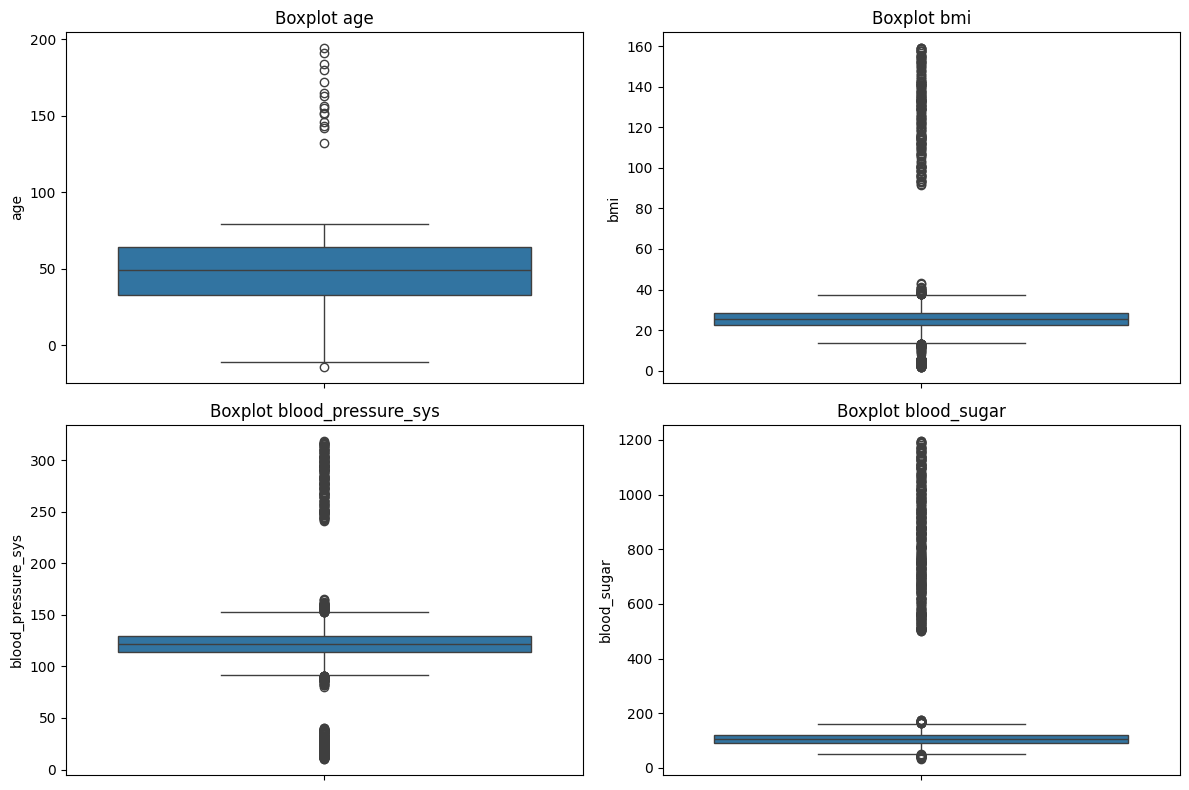

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

kolom = ['age', 'bmi', 'blood_pressure_sys', 'blood_sugar']

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for col, ax in zip(kolom, axes.flatten()):
    sns.boxplot(y=df_clean[col], ax=ax)
    ax.set_title(f'Boxplot {col}')

plt.tight_layout()
plt.show()

Analisis Hasil Boxplot

1. Age: Sebagian besar usia berada pada rentang 33–64 tahun, dengan median sekitar 49 tahun. Terdapat kandidat outlier berupa usia negatif dan usia di atas 100 hingga mendekati 200 tahun.
2. BMI: Sebagian besar nilai BMI berada pada rentang 22,5–28,5, dengan median 25,4. Terlihat kandidat outlier di bawah 13 dan di atas 38 hingga sekitar 159.
3. Blood Pressure Systolic: Sebagian besar nilai berada pada rentang 113–130. Terdapat kandidat outlier di bawah 90 dan di atas 150, bahkan mencapai lebih dari 300.
4. Blood Sugar: Sebagian besar nilai berada pada rentang 90–120. Terdapat kandidat outlier di bawah 45 dan di atas 160, bahkan mencapai sekitar 1.200.

Secara keseluruhan, keempat kolom menunjukkan adanya kandidat outlier yang perlu diperiksa lebih lanjut menggunakan metode IQR.

IQR (Interquartile Range) cocok sebagai metode memeriksa outlier. Alasannya:
* IQR cocok untuk mendeteksi nilai ekstrem.
* Tidak terlalu terpengaruh oleh nilai ekstrem itu sendiri.
* Batas outlier IQR sesuai dengan konsep boxplot yang digunakan

In [ ]:
kolom = ['age', 'bmi', 'blood_pressure_sys', 'blood_sugar']

for col in kolom:
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)
    IQR = Q3 - Q1

    batas_bawah = Q1 - (1.5 * IQR)
    batas_atas = Q3 + (1.5 * IQR)

    outlier = df_clean[
        (df_clean[col] < batas_bawah) |
        (df_clean[col] > batas_atas)
    ]

    print(f'Kolom: {col}')
    print(f'Batas bawah: {batas_bawah:.2f}')
    print(f'Batas atas: {batas_atas:.2f}')
    print(f'Jumlah outlier: {len(outlier)}')
    print('---------------------------')

Kolom: age
Batas bawah: -13.50
Batas atas: 110.50
Jumlah outlier: 16
---------------------------
Kolom: bmi
Batas bawah: 13.50
Batas atas: 37.50
Jumlah outlier: 464
---------------------------
Kolom: blood_pressure_sys
Batas bawah: 91.30
Batas atas: 152.90
Jumlah outlier: 500
---------------------------
Kolom: blood_sugar
Batas bawah: 50.55
Batas atas: 162.15
Jumlah outlier: 451
---------------------------


Untuk menghandle outliers pada IQR bisa dilakukan dengan menghapus atau Winsorization, menghapus baris akan beresiko kehilangan data pasien. Yaitu dengan cara:
*   Jika nilai > batas atas → diganti dengan batas atas
*   Jika nilai < batas bawah → diganti dengan batas bawah

Diterapkan pada kolom:
* Nilai age negatif diubah menjadi missing value, lalu diisi median. Karena tidak valid
* Nilai ekstrem lainnya pada age, BMI, blood pressure, dan blood sugar ditangani dengan Winsorization.




In [ ]:
kolom = ['age', 'bmi', 'blood_pressure_sys', 'blood_sugar']

df_winsor = df_clean.copy()

# Mengubah usia negatif menjadi missing value
df_winsor.loc[df_winsor['age'] < 0, 'age'] = float('nan')

# Mengisi usia negatif dengan median
df_winsor['age'] = df_winsor['age'].fillna(
    df_winsor['age'].median()
)

# Winsorization menggunakan IQR
for col in kolom:
    Q1 = df_winsor[col].quantile(0.25)
    Q3 = df_winsor[col].quantile(0.75)
    IQR = Q3 - Q1

    batas_bawah = Q1 - (1.5 * IQR)
    batas_atas = Q3 + (1.5 * IQR)

    df_winsor[col] = df_winsor[col].clip(
        lower=batas_bawah,
        upper=batas_atas
    )

print("Penanganan outlier berhasil diterapkan.")

Penanganan outlier berhasil diterapkan.


In [ ]:
kolom = ['age', 'bmi', 'blood_pressure_sys', 'blood_sugar']

for col in kolom:
    print(f'\nKolom: {col}')
    print('======Sebelum======')
    print(df_clean[col].describe())

    print('======Sesudah======')
    print(df_winsor[col].describe())


Kolom: age
======Sebelum======
count    10000.000000
mean        48.553900
std         18.484114
min        -14.000000
25%         33.000000
50%         49.000000
75%         64.000000
max        194.000000
Name: age, dtype: float64
======Sesudah======
count    10000.000000
mean        48.561750
std         17.971631
min         18.000000
25%         33.000000
50%         49.000000
75%         64.000000
max        110.500000
Name: age, dtype: float64

Kolom: bmi
======Sebelum======
count    10000.000000
mean        26.988320
std         15.166022
min          2.000000
25%         22.500000
50%         25.400000
75%         28.500000
max        158.900000
Name: bmi, dtype: float64
======Sesudah======
count    10000.000000
mean        25.456450
std          4.911503
min         13.500000
25%         22.500000
50%         25.400000
75%         28.500000
max         37.500000
Name: bmi, dtype: float64

Kolom: blood_pressure_sys
======Sebelum======
count    10000.000000
mean       123.2693